# Early momentum forecasting

Team B09: Aryan Jain, Ahrar Karim, Drishti Chulani, Linh Le, Sai Leela Rahul Pujari

Dataset: [Olist Brazilian E-commerce Public Dataset (2016–2018)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce/data)



Link to the collab file: https://drive.google.com/file/d/1FQHHjC4g98R9T_1YLuvtLpsVWRc4Wm7X/view?usp=sharing


## Table of Contents

>[Best Seller Product Prediction](#scrollTo=oIiHJSNW9Do8)

>>[Problem Statement](#scrollTo=Nab1WYtRBmiS)

>>[Exploratory Data Analysis](#scrollTo=BNTjRsGLjK__)

>>>[Pareto curve](#scrollTo=1EjwvwIq-78u)

>>>[Early-Momentum Lift Curve](#scrollTo=KKf8iHzw-4Tq)

>>>[Customer Satisfaction Distribution](#scrollTo=cicodT-FeXQ7)

>>>[Insights:](#scrollTo=_WYn5g5Jn1xG)

>>>[Data Information](#scrollTo=8wnxYNHmDK5H)

>>[Label Construction](#scrollTo=M5JEYiATBR9C)

>>[Feature Engineering & Train/Test Split](#scrollTo=bYn3hISQ_2s8)

>>[Modeling (5 models + tuning)](#scrollTo=pUNW04gqxKZN)

>>[Visualization](#scrollTo=Ei_4BoXYAdE6)

>>[Final Results & Interpretation](#scrollTo=y7QIZsaoArYW)

>>>[Evaluation Metric](#scrollTo=y7QIZsaoArYW)

>>[Gen AI Disclosure](#scrollTo=3X1_Uj_O6mpB)



## 1. Problem Statement
<a id="problem-statement"></a>

For a marketplace where a small share of products drives most of the revenue, the business needs not only to predict which new products will become top performers within their first few days of launch, but also to understand how they build that performance over time. Using the Olist Brazilian e‑commerce dataset, this project builds a product‑level model that predicts whether a new product will fall into the top 10% by units sold in its first 60 days and segments products into early‑momentum profiles based on the ratio of sales, using only features available in the first 7–14 days.



## 2. Exploratory Data Analysis
<a id="exploratory-data-analysis"></a>

### Pareto curve
This chart plots the cumulative share of total revenue (y-axis) against the cumulative share of products (x-axis), sorted from highest- to lowest-earning.

It’s a visualization of the Pareto principle (80/20 rule) — the idea that a small portion of products generate most of the revenue.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
items = pd.read_csv("/content/olist_order_items_dataset.csv")
orders = pd.read_csv("/content/olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
reviews = pd.read_csv("/content/olist_order_reviews_dataset.csv")
product = pd.read_csv("/content/olist_products_dataset.csv")

In [ ]:
file_name = 'https://drive.google.com/uc?export=download&id=13bQQfKDjiuBA1njsvCEW81c4Q2huRE9z'
data = pd.read_csv(file_name)

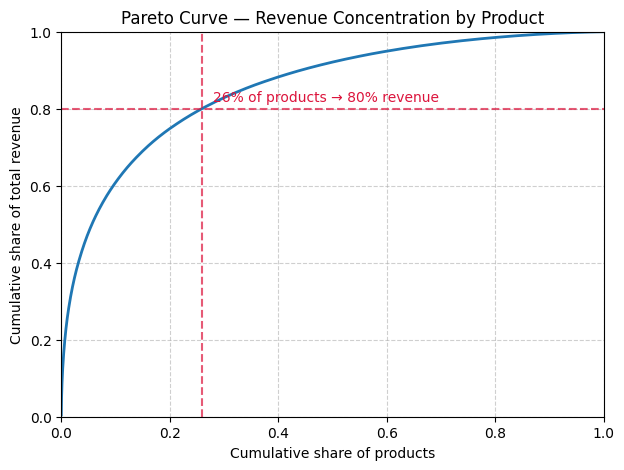

In [ ]:
# 1) Revenue per product
#    (In Olist, `price` is the line price; summing gives observed revenue per product.)
revenue = (items.groupby("product_id", as_index=False)
                 .agg(revenue=("price","sum")))

# 2) Sort by revenue desc and compute cumulative shares (0..1)
revenue = revenue.sort_values("revenue", ascending=False).reset_index(drop=True)
revenue["cum_revenue_share"] = revenue["revenue"].cumsum() / revenue["revenue"].sum()
revenue["cum_product_share"] = (revenue.index + 1) / len(revenue)

# 3) Find x where we hit 80% of revenue
idx80 = int(np.argmax(revenue["cum_revenue_share"].values >= 0.80))
x80 = float(revenue.loc[idx80, "cum_product_share"])

# 4) Plot properly bounded to [0,1]
plt.figure(figsize=(7,5))
plt.plot(revenue["cum_product_share"], revenue["cum_revenue_share"], lw=2)
plt.axhline(0.80, linestyle="--", color="crimson", alpha=0.7)
plt.axvline(x80, linestyle="--", color="crimson", alpha=0.7)
plt.xlim(0,1); plt.ylim(0,1)
plt.xlabel("Cumulative share of products")
plt.ylabel("Cumulative share of total revenue")
plt.title("Pareto Curve — Revenue Concentration by Product")
plt.grid(True, linestyle="--", alpha=0.6)
plt.text(min(x80+0.02,0.95), 0.82, f"{x80:.0%} of products → 80% revenue", color="crimson")
plt.show()


This significant skew means that a 1% improvement in correctly predicting the top-performing products could unlock an outsized return in revenue by optimizing marketing and inventory.

Why it Motivates

The marketplace is winner-take-most.
With only a quarter of the catalog producing the majority of revenue, correctly identifying those “winners” early has huge business value.

Predicting early success can guide decisions.
If we can forecast which products will become bestsellers in their first 60 days, we can:

Promote them on the homepage or ads,

Allocate inventory and logistics efficiently,

Avoid overstocking low-performing “dead” item

### Early-Momentum Lift Curve

What it shows: If you rank products by first-7-day units, how much of total 60-day units do the top X% capture?
Why it motivates: If the curve is steep above the diagonal baseline, early momentum is predictive—so a model using ≤7-day signals makes sense.

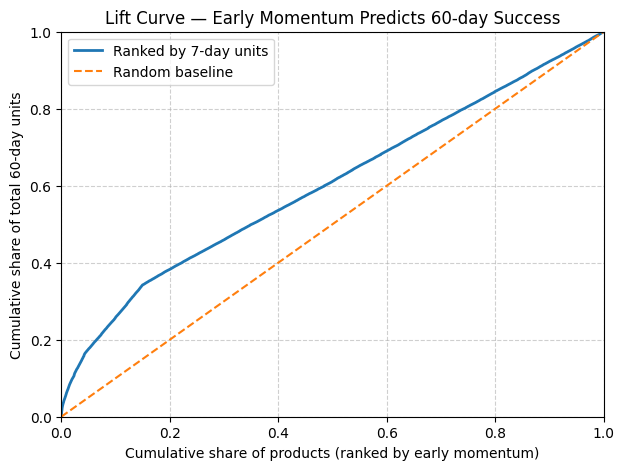

In [ ]:
# Launch date per product = first purchase timestamp
oi = items.merge(orders[["order_id","order_purchase_timestamp"]], on="order_id", how="left")
launch = oi.groupby("product_id")["order_purchase_timestamp"].min().rename("launch_ts")
oi = oi.merge(launch, on="product_id", how="left")

within7  = (oi["order_purchase_timestamp"] >= oi["launch_ts"]) & (oi["order_purchase_timestamp"] < oi["launch_ts"] + pd.Timedelta(days=7))
within60 = (oi["order_purchase_timestamp"] >= oi["launch_ts"]) & (oi["order_purchase_timestamp"] < oi["launch_ts"] + pd.Timedelta(days=60))

# Early momentum & eventual outcome
u7  = oi[within7].groupby("product_id")["order_item_id"].count().rename("units7")
u60 = oi[within60].groupby("product_id")["order_item_id"].count().rename("units60")

df = (pd.concat([u7,u60], axis=1).fillna(0).astype(int)
        .sort_values("units7", ascending=False).reset_index())

# Cumulative capture of 60-day units by top X% ranked on 7-day units
df["cum_units60"] = df["units60"].cumsum()
df["cum_share_products"] = (np.arange(1, len(df)+1)) / len(df)
df["cum_share_units60"]  = df["cum_units60"] / df["units60"].sum()

plt.figure(figsize=(7,5))
plt.plot(df["cum_share_products"], df["cum_share_units60"], lw=2, label="Ranked by 7-day units")
plt.plot([0,1],[0,1], "--", label="Random baseline")
plt.xlim(0,1); plt.ylim(0,1)
plt.xlabel("Cumulative share of products (ranked by early momentum)")
plt.ylabel("Cumulative share of total 60-day units")
plt.title("Lift Curve — Early Momentum Predicts 60-day Success")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()


Only a small fraction of products (those that sell quickly in the first 7 days) drive a disproportionate share of long-term sales.

Therefore, if we can predict which products will take off early, we can act before 60 days — promote them, stock them, or adjust prices for laggards.

### Customer Satisfaction Distribution
What it shows:
This chart displays the frequency of customer review scores (1–5 stars) across all orders in the Olist dataset. Each bar represents how many reviews fall into that rating category. The top 20% of products (ranked by 7-day units) capture approximately 40-45% of the total 60-day units.



Why it motivates: Customer sentiment often correlates with both short-term sales velocity and long-term retention. Products receiving higher ratings early in their lifecycle are more likely to sustain sales momentum and visibility.
Understanding the distribution of satisfaction scores also helps interpret noise and bias in feedback-based features since most e-commerce platforms exhibit a strong positive skew toward 4–5 star reviews.

count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64


/tmp/ipython-input-587195617.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="review_score", data=reviews, palette="crest")


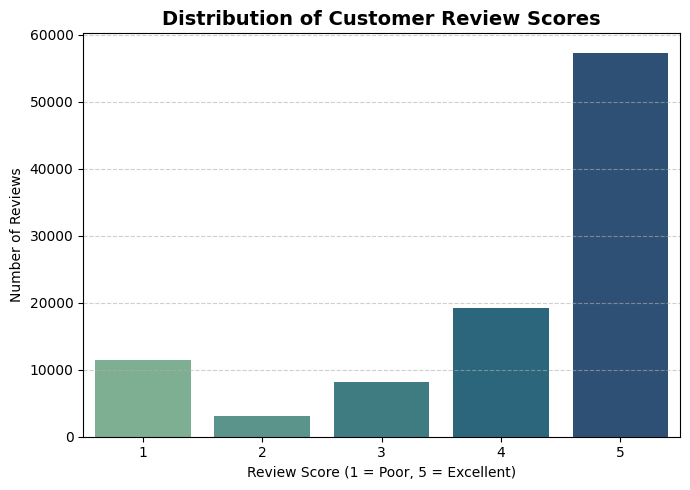

In [ ]:
#working on Review dataset

# Basic sanity check
print(reviews["review_score"].describe())

# Plot histogram of review scores
plt.figure(figsize=(7,5))
sns.countplot(x="review_score", data=reviews, palette="crest")

plt.title("Distribution of Customer Review Scores", fontsize=14, weight="bold")
plt.xlabel("Review Score (1 = Poor, 5 = Excellent)")
plt.ylabel("Number of Reviews")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


Interpretation:
As seen in Figure 3, the majority of reviews are 4 or 5 stars, indicating generally high customer satisfaction. However, the presence of low-rated reviews provides variation that can be leveraged as a predictive signal in modeling for instance, linking poor early ratings to reduced best-seller likelihood.

### Insights:


- The Business Problem: The Pareto Curve confirms that 26% of products generate 80% of revenue, making the early identification of these 'winners' a high-value business priority.

- The Predictive Feasibility: The Lift Curve demonstrates that early sales (7-day units) are highly predictive of long-term success (60-day units), confirming that signals captured in the first week are sufficient to build an effective forecasting model.

- A Key Signal: The Distribution of Customer Review Scores identifies customer sentiment as a crucial feature, with the variation in rare, low-rated reviews providing powerful, actionable signals for model construction.

### Data Information

In [ ]:
# Merge items with orders and reviews and products

df = (
    items
    .merge(product[['product_id', 'product_category_name']], on="product_id", how="left")
    .merge(orders, on="order_id", how="left")
    .merge(reviews[['order_id', 'review_score']], on="order_id", how="left")
)
# Inspect combined dataset
print(df.shape)
print(df.head())
print(df.columns)


(113314, 16)
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value product_category_name  \
0  2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1  2017-05-03 11:05:13  239.90          19.93              pet_shop   
2  2018-01

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113314 entries, 0 to 113313
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       113314 non-null  object        
 1   order_item_id                  113314 non-null  int64         
 2   product_id                     113314 non-null  object        
 3   seller_id                      113314 non-null  object        
 4   shipping_limit_date            113314 non-null  object        
 5   price                          113314 non-null  float64       
 6   freight_value                  113314 non-null  float64       
 7   product_category_name          111702 non-null  object        
 8   customer_id                    113314 non-null  object        
 9   order_status                   113314 non-null  object        
 10  order_purchase_timestamp       113314 non-null  datetime64[ns]
 11  

In [ ]:
df.describe()

,order_item_id,price,freight_value,order_purchase_timestamp,review_score
count,113314.000000,113314.000000,113314.000000,113314,112372.000000
mean,1.198528,120.478701,19.979428,2017-12-31 15:03:55.044654848,4.032473
min,1.000000,0.850000,0.000000,2016-09-04 21:15:19,1.000000
25%,1.000000,39.900000,13.080000,2017-09-13 12:53:41.249999872,4.000000
50%,1.000000,74.900000,16.260000,2018-01-19 14:34:32,5.000000
75%,1.000000,134.900000,21.150000,2018-05-04 11:08:28,5.000000
max,21.000000,6735.000000,409.680000,2018-09-03 09:06:57,5.000000
std,0.707016,183.279678,15.783227,NaN,1.387849


In [ ]:
# Save the merged dataset to a CSV file
output_path = "/content/olist_combined_dataset.csv"
df.to_csv(output_path, index=False)

print(f"✅ Combined dataset saved to: {output_path}")


✅ Combined dataset saved to: /content/olist_combined_dataset.csv


In [ ]:
df.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0
product_category_name,1612
customer_id,0
order_status,0


In [ ]:
#changing the Datatype from object to Datetime

date_cols = [
    'shipping_limit_date',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

df[date_cols].dtypes

,0
shipping_limit_date,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [ ]:
#Delay in time , actual delivered- estimated

df['delivery_delay_days'] = (df['order_delivered_customer_date'] -
                        df['order_estimated_delivery_date']).dt.days

In [ ]:
df['purchase_month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['purchase_monthyear'] = df['order_purchase_timestamp'].dt.to_period('M')

In [ ]:
# Delivery time purchase to customer

df['delivery_time_days'] = (
    df['order_delivered_customer_date'] - df['order_purchase_timestamp']
).dt.days

In [ ]:
#Total item revenue

df['item_revenue'] = df['price'] + df['freight_value']

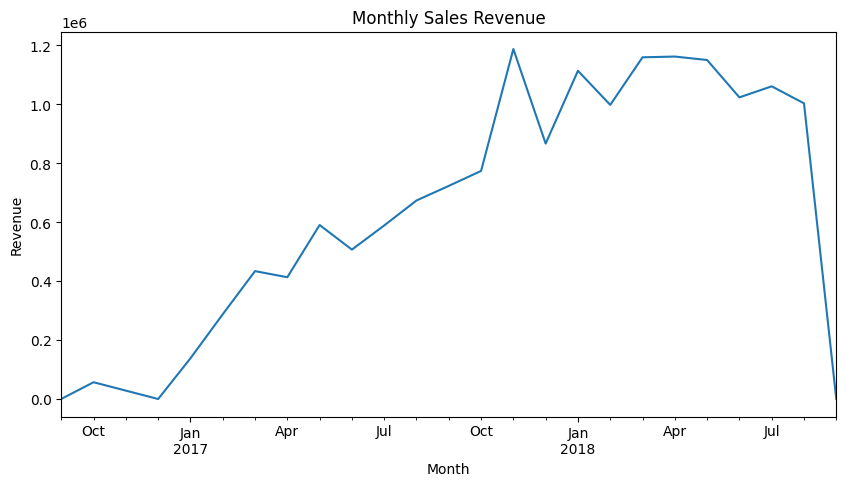

In [ ]:
monthly_sales = df.groupby('purchase_month')['item_revenue'].sum()

monthly_sales.plot(figsize=(10,5))
plt.title("Monthly Sales Revenue")
plt.ylabel("Revenue")
plt.xlabel("Month")
plt.show()

In [ ]:
df.groupby('purchase_monthyear')['order_id'].count()

,order_id
purchase_monthyear,
2016-09,6
2016-10,367
2016-12,1
2017-01,966
2017-02,1962
2017-03,3020
2017-04,2693
2017-05,4182
2017-06,3619


                        count  percentage     revenue
product_category_name                                
beleza_saude             9727        8.71  1263138.54
relogios_presentes       6001        5.37  1206075.33
cama_mesa_banho         11270       10.09  1050936.61
esporte_lazer            8700        7.79   993656.51
informatica_acessorios   7894        7.07   919640.54


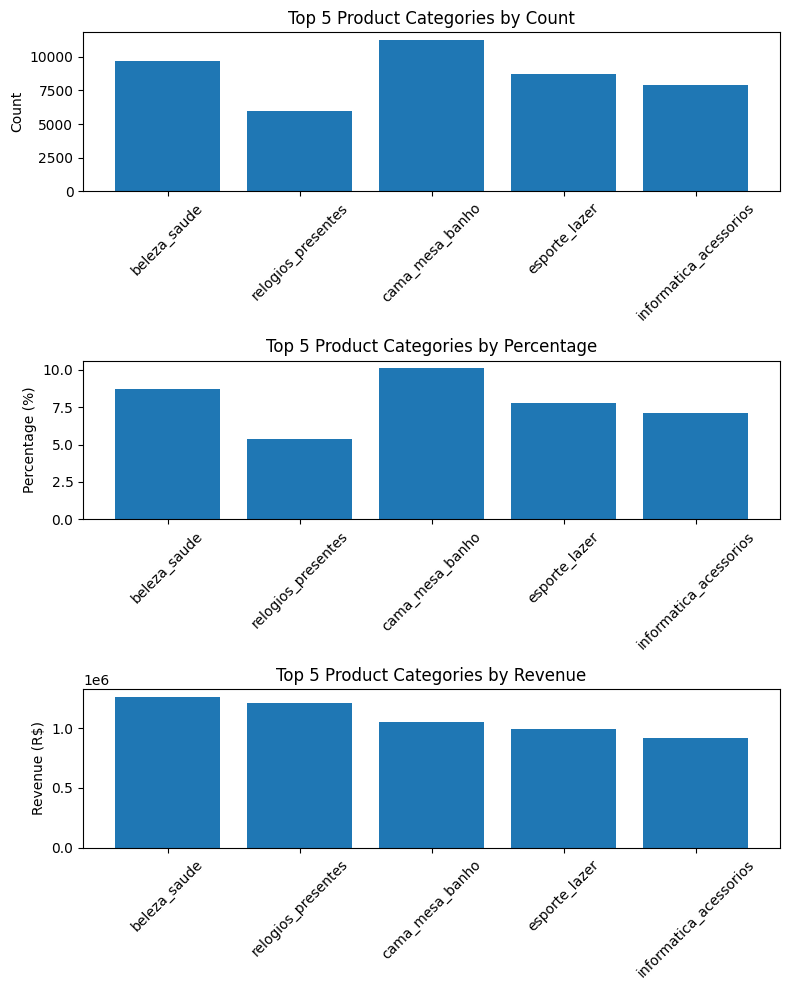

In [ ]:
# Top 5 Product Categories by count, percentage and Revenue
summary = pd.DataFrame({
    "count": df['product_category_name'].value_counts(),
    "percentage": df['product_category_name'].value_counts(normalize=True) * 100,
    "revenue": df.groupby('product_category_name')['price'].sum()
})

summary['percentage'] = summary['percentage'].round(2)

# Sort by count and show top 5
top5 = summary.sort_values("revenue", ascending=False).head(5)

print(top5)

plt.figure(figsize=(8, 10))

# Count
plt.subplot(3, 1, 1)
plt.bar(top5.index, top5['count'])
plt.title("Top 5 Product Categories by Count")
plt.ylabel("Count")
plt.xticks(rotation=45)

# Percentage
plt.subplot(3, 1, 2)
plt.bar(top5.index, top5['percentage'])
plt.title("Top 5 Product Categories by Percentage")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)

# Revenue
plt.subplot(3, 1, 3)
plt.bar(top5.index, top5['revenue'])
plt.title("Top 5 Product Categories by Revenue")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Translation of the 5 product categories are

| product_category_name | count | percentage | revenue |
|------------------------|-------|------------|----------|
| beauty_health          | 9727  | 8.71       | 1,263,138.54 |
| watches_gifts          | 6001  | 5.37       | 1,206,075.33 |
| bed_bath_table         | 11270 | 10.09      | 1,050,936.61 |
| sports_leisure         | 8700  | 7.79       | 993,656.51 |
| computers_accessories  | 7894  | 7.07       | 919,640.54 |

The category with the highest revenue is 'beleza_saude' with a total revenue of $1263138.54.



/tmp/ipython-input-4196354713.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


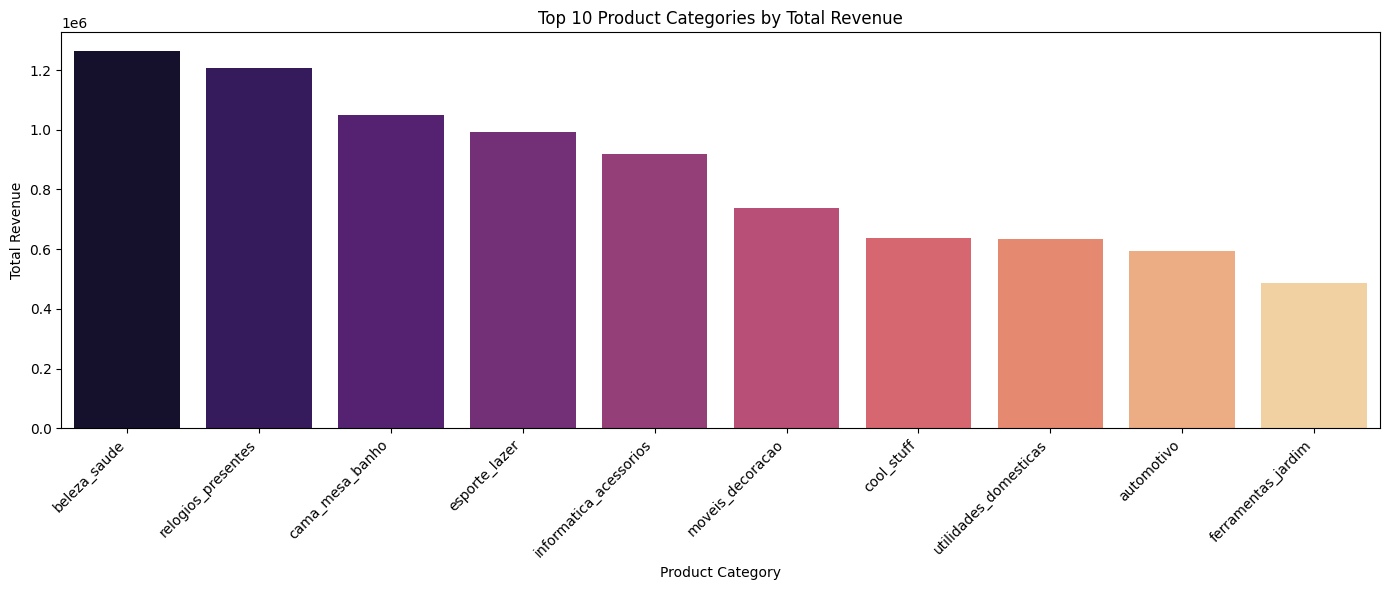

In [ ]:
# Merge into single df, now including product_category_name
df = (
    items
    .merge(orders, on="order_id", how="left")
    .merge(reviews[["order_id", "review_score"]], on="order_id", how="left")
    .merge(product[["product_id", "product_category_name"]], on="product_id", how="left")  # <- change here
)

# Calculate total revenue per category
category_revenue = (
    df.groupby("product_category_name")["price"]
      .sum()
      .reset_index()
)

# Sort by revenue in descending order
top_category_revenue = category_revenue.sort_values(by="price", ascending=False)

# Get category with highest revenue
highest_rev_cat = top_category_revenue.iloc[0]
print(
    f"The category with the highest revenue is '{highest_rev_cat['product_category_name']}' "
    f"with a total revenue of ${highest_rev_cat['price']:.2f}.\n"
)

# Plot top 10 categories by revenue
plt.figure(figsize=(14, 6))
sns.barplot(
    x="product_category_name",
    y="price",
    data=top_category_revenue.head(10),
    palette="magma"
)
plt.title("Top 10 Product Categories by Total Revenue")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Fastest selling category: cama_mesa_banho (13911 units sold)



/tmp/ipython-input-2480787699.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


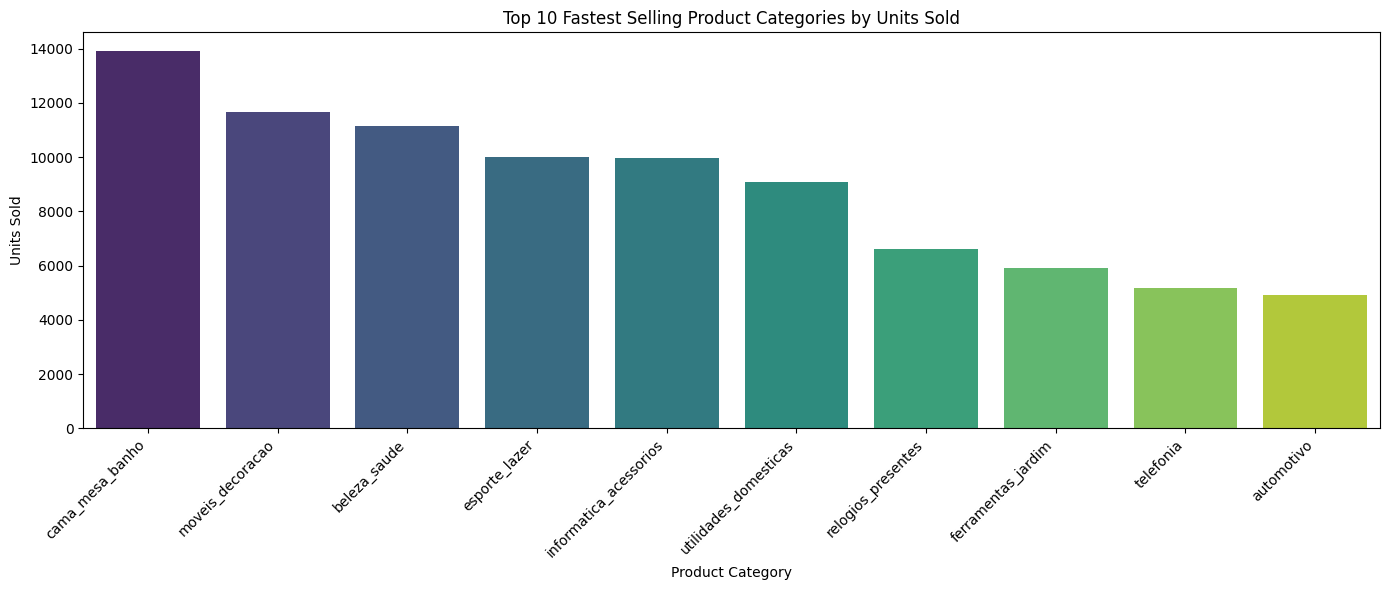

In [ ]:
# Group by category
category_units = (
    df.groupby('product_category_name')['order_item_id']
      .sum()
      .reset_index()
)

# Sort
fastest_selling_categories = category_units.sort_values(by='order_item_id', ascending=False)

# Print #1
top_cat = fastest_selling_categories.iloc[0]
print(
    f"Fastest selling category: {top_cat['product_category_name']} "
    f"({top_cat['order_item_id']} units sold)\n"
)

# Plot
plt.figure(figsize=(14, 6))
sns.barplot(
    x='product_category_name',
    y='order_item_id',
    data=fastest_selling_categories.head(10),
    palette='viridis'
)
plt.title('Top 10 Fastest Selling Product Categories by Units Sold')
plt.xlabel('Product Category')
plt.ylabel('Units Sold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
#Freight share of product price

df['freight_ratio'] = df['freight_value'] / df['price']

In [ ]:
# Make sure datetime columns are in datetime format
date_cols = [
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Compute delivery_delay_days
df['delivery_delay_days'] = (
    df['order_delivered_customer_date'] - df['order_estimated_delivery_date']
).dt.days


#late flag
df['is_late'] = (df['delivery_delay_days'] > 0).astype(int)

#missing values in the date
df['delivered_flag'] = df['order_delivered_customer_date'].notnull().astype(int)

#flag the missing review scores
df['has_review'] = df['review_score'].notnull().astype(int)

In [ ]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], errors='coerce')
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'], errors='coerce')

# Recompute delivery_time_days (delivery - purchase)
df['delivery_time_days'] = (
    df['order_delivered_customer_date'] - df['order_purchase_timestamp']
).dt.days


df[(df['delivery_time_days'] > 60) | (df['delivery_time_days'] < 0)]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_delivered_customer_date,order_estimated_delivery_date,review_score,product_category_name,freight_ratio,delivery_delay_days,is_late,delivered_flag,has_review,delivery_time_days
227,0096668e5b0b8e9657a6f7209a4e58b4,1,55782cb82e0efe052da0a3da237da3b2,c003204e1ab016dfa150abc119207b24,2018-07-13 13:46:36,166.90,13.47,b6fbaad4eb3a0794111683dca8122610,delivered,2018-07-11 13:33:21,...,2018-09-17 14:42:46,2018-07-19,4.0,automotivo,0.080707,60.0,1,1,1,68.0
341,00d1289d5125017a90e528b5a7cee91f,1,a60613d36f37a7b27d3344f40f6a7945,ad420dd0c4f92f8af951ac24b86d0cf5,2018-03-21 11:29:14,160.00,19.00,ba0ff1667f88b3a0da55d80dff50b0fb,delivered,2018-03-15 11:11:52,...,2018-06-19 18:42:26,2018-04-06,1.0,beleza_saude,0.118750,74.0,1,1,1,96.0
856,01f67ca8027e959060afd840aa06f465,1,bb50f2e236e5eea0100680137654686c,f7ba60f8c3f99e7ee4042fdef03b70c4,2018-05-08 09:31:23,330.00,14.70,1b606aeedafbe92f4c55f4fcad9dbcb4,delivered,2018-04-30 16:19:48,...,2018-07-04 18:47:45,2018-05-24,1.0,beleza_saude,0.044545,41.0,1,1,1,65.0
1341,031e7d4e559a1bf08e71a419aa998d0a,1,fb1f078a066428f00c1d71d6b9df3ff8,eebb3372362aa9a46975164bed19a7e7,2017-04-12 13:10:41,73.99,24.52,aedfc62ab52a3e4ea642220ccdec91ff,delivered,2017-04-06 12:59:46,...,2017-09-19 16:23:52,2017-05-19,1.0,telefonia,0.331396,123.0,1,1,1,166.0
1463,0359008adff4c1def5a09bb92f7a5aa8,1,3e49ed0eb3b0fd7c15032a2e250d43d5,5058e8c1e82653974541e83690655b4a,2018-04-19 02:40:38,239.99,70.54,dcc777d07a081464e7a71921cc13cde0,delivered,2018-03-15 13:17:11,...,2018-05-16 22:38:23,2018-05-02,5.0,moveis_escritorio,0.293929,14.0,1,1,1,62.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111535,fbee80ef6891c144af8ff9dc788aaa89,1,89c111575a1b19782a2e660eff07dd8a,54a1852d1b8f10312c55e906355666ee,2017-01-16 12:01:14,33.90,24.84,41ee1607f629eea5c7aa658053748326,delivered,2017-01-12 12:01:14,...,2017-04-26 09:35:51,2017-03-06,1.0,fashion_bolsas_e_acessorios,0.732743,51.0,1,1,1,103.0
111773,fc74153e0ac39bb68c8f8f9e4758f001,1,595fac2a385ac33a80bd5114aec74eb8,ef0ace09169ac090589d85746e3e036f,2018-04-19 12:50:48,117.70,51.32,787c8dad81798b72c5ae7d0ed526192e,delivered,2018-04-12 12:40:46,...,2018-06-29 17:03:25,2018-05-11,1.0,perfumaria,0.436024,49.0,1,1,1,78.0
112164,fd4db108a62ede2be6aa8ef940b04fee,1,e6fc61fe224249bd106fec6e1751a586,fa1c13f2614d7b5c4749cbc52fecda94,2018-03-13 20:29:33,199.90,19.28,9e7d7aac45876ccdebb580ef0854d5d2,delivered,2018-03-07 20:10:55,...,2018-06-01 17:02:26,2018-04-02,5.0,relogios_presentes,0.096448,60.0,1,1,1,85.0
112273,fd84aa1fc4c825c367cbb777d82e5a2a,1,52d7a7207b9646509bdc754fed3a0cef,26e2c91ef821e1ff8985f408788fe35b,2018-02-28 23:30:22,57.50,16.84,11e6c1e1c69c492681319ffe14aab2eb,delivered,2018-02-24 23:18:14,...,2018-05-11 19:32:35,2018-03-27,5.0,cama_mesa_banho,0.292870,45.0,1,1,1,75.0


In [ ]:
df

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_delivered_customer_date,order_estimated_delivery_date,review_score,product_category_name,freight_ratio,delivery_delay_days,is_late,delivered_flag,has_review,delivery_time_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09-20 23:43:48,2017-09-29,5.0,cool_stuff,0.225637,-9.0,0,1,1,7.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-05-12 16:04:24,2017-05-15,4.0,pet_shop,0.083076,-3.0,0,1,1,16.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-01-22 13:19:16,2018-02-05,5.0,moveis_decoracao,0.089799,-14.0,0,1,1,7.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,2018-08-14 13:32:39,2018-08-20,4.0,perfumaria,0.984604,-6.0,0,1,1,6.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,2017-03-01 16:42:31,2017-03-17,5.0,ferramentas_jardim,0.090745,-16.0,0,1,1,25.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113309,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,...,2018-05-10 22:56:40,2018-05-18,5.0,utilidades_domesticas,0.144705,-8.0,0,1,1,17.0
113310,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,...,2018-07-23 20:31:55,2018-08-01,5.0,informatica_acessorios,0.104371,-9.0,0,1,1,9.0
113311,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,...,2017-10-28 12:22:22,2017-11-10,5.0,esporte_lazer,0.169670,-13.0,0,1,1,4.0
113312,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,...,2017-08-16 21:59:40,2017-08-25,5.0,informatica_acessorios,0.155742,-9.0,0,1,1,1.0


## 3. Label Construction

In [ ]:
import numpy as np
import pandas as pd

# ============================================================
# LABEL CREATION + EARLY-MOMENTUM FEATURES
# ============================================================

# 1) Ensure product_id is string everywhere we need it
df["product_id"] = df["product_id"].astype(str)

oi_for_label_construction = df[['product_id', 'order_id', 'order_item_id', 'order_purchase_timestamp']].copy()

# 2) Build launch timestamp per product using the global 'df'
launch = (
    oi_for_label_construction.groupby("product_id")["order_purchase_timestamp"]
      .min()
      .rename("launch_ts")
)

oi_for_label_construction = oi_for_label_construction.merge(launch, on="product_id", how="left")

# 3) Helper to compute units sold in the first N days after launch
def units_in_window(days: int) -> pd.Series:
    mask = (
        (oi_for_label_construction["order_purchase_timestamp"] >= oi_for_label_construction["launch_ts"]) &
        (oi_for_label_construction["order_purchase_timestamp"] < oi_for_label_construction["launch_ts"] + pd.Timedelta(days=days))
    )
    return (
        oi_for_label_construction[mask]
        .groupby("product_id")["order_item_id"]
        .count()
        .rename(f"units{days}")
    )

# 4) Compute 7, 14, and 60-day unit counts per product
u7  = units_in_window(7)
u14 = units_in_window(14)
u60 = units_in_window(60)

# Combine into a single product-level table
product_sales = (
    pd.concat([u7, u14, u60], axis=1)
      .fillna(0)
      .reset_index()
      .rename(columns={"product_id": "product_id"})
)

product_sales["product_id"] = product_sales["product_id"].astype(str)

# Print a sanity check for product_sales
print("Product sales head after initial computation:")
display(product_sales.head())
print("Units7 min/max/mean:", product_sales['units7'].min(), product_sales['units7'].max(), product_sales['units7'].mean())


Product sales head after initial computation:


,product_id,units7,units14,units60
0,00066f42aeeb9f3007548bb9d3f33c38,1,1,1
1,00088930e925c41fd95ebfe695fd2655,1,1,1
2,0009406fd7479715e4bef61dd91f2462,1,1,1
3,000b8f95fcb9e0096488278317764d19,1,2,2
4,000d9be29b5207b54e86aa1b1ac54872,1,1,1


Units7 min/max/mean: 1 29 1.2489454037813723


In [ ]:
# 5) Early momentum features: ratio of early units to 60-day units
product_sales["early_momentum_7"] = np.where(
    product_sales["units60"] > 0,
    product_sales["units7"] / product_sales["units60"],
    0.0,
)

product_sales["early_momentum_14"] = np.where(
    product_sales["units60"] > 0,
    product_sales["units14"] / product_sales["units60"],
    0.0,
)

# 6) MAIN LABEL: Best_Seller_60
#    Top 10% of products ranked by 60-day units
threshold_60 = product_sales["units60"].quantile(0.90)
product_sales["Best_Seller_60"] = (product_sales["units60"] >= threshold_60).astype(int)

# 7- and 14-day "top 10%" labels:
threshold_7  = product_sales["units7"].quantile(0.90)
threshold_14 = product_sales["units14"].quantile(0.90)

product_sales["Best_Seller_7"]  = (product_sales["units7"]  >= threshold_7).astype(int)
product_sales["Best_Seller_14"] = (product_sales["units14"] >= threshold_14).astype(int)

# Ratio-based labels: 90% of 60-day units sold in first 7/14 days
product_sales["units_sold_7_days_ratio"] = np.where(
    product_sales["units60"] > 0,
    product_sales["units7"] / product_sales["units60"],
    0.0,
)
product_sales["units_sold_14_days_ratio"] = np.where(
    product_sales["units60"] > 0,
    product_sales["units14"] / product_sales["units60"],
    0.0,
)

product_sales["best_seller_label_7"] = (
    product_sales["units_sold_7_days_ratio"] >= 0.90
).astype(int)

product_sales["best_seller_label_14"] = (
    product_sales["units_sold_14_days_ratio"] >= 0.90
).astype(int)

# 7) Merge labels + early-sales features back into main df (order-item level)
label_cols = [
    "product_id",
    "units7",
    "units14",
    "units60",
    "early_momentum_7",
    "early_momentum_14",
    "Best_Seller_60",
    "Best_Seller_7",
    "Best_Seller_14",
    "best_seller_label_7",
    "best_seller_label_14",
]

df = df.merge(product_sales[label_cols], on="product_id", how="left")

# 8) Quick sanity check
display(
    df[[
        "product_id",
        "units7", "units14", "units60",
        "early_momentum_7", "early_momentum_14",
        "Best_Seller_60", "Best_Seller_7", "Best_Seller_14",
        "best_seller_label_7", "best_seller_label_14",
    ]].head()
)

# products labeled positive under each definition
for col_name in ["Best_Seller_60", "Best_Seller_14", "Best_Seller_7",
                 "best_seller_label_7", "best_seller_label_14"]:
    if col_name in df.columns:
        n_pos = df[df[col_name] == 1]["product_id"].nunique()
        print(f"Number of products with {col_name} = 1: {n_pos}")

,product_id,units7,units14,units60,early_momentum_7,early_momentum_14,Best_Seller_60,Best_Seller_7,Best_Seller_14,best_seller_label_7,best_seller_label_14
0,4244733e06e7ecb4970a6e2683c13e61,1,1,4,0.25,0.25,1,0,0,0,0
1,e5f2d52b802189ee658865ca93d83a8f,1,1,1,1.00,1.00,0,0,0,1,1
2,c777355d18b72b67abbeef9df44fd0fd,1,1,1,1.00,1.00,0,0,0,1,1
3,7634da152a4610f1595efa32f14722fc,1,2,2,0.50,1.00,0,0,1,0,1
4,ac6c3623068f30de03045865e4e10089,1,1,1,1.00,1.00,0,0,0,1,1


Number of products with Best_Seller_60 = 1: 5037
Number of products with Best_Seller_14 = 1: 6562
Number of products with Best_Seller_7 = 1: 5116
Number of products with best_seller_label_7 = 1: 25400
Number of products with best_seller_label_14 = 1: 26395


In [ ]:
display(df[['product_id', 'best_seller_label_14', 'best_seller_label_7']])

,product_id,best_seller_label_14,best_seller_label_7
0,4244733e06e7ecb4970a6e2683c13e61,0,0
1,e5f2d52b802189ee658865ca93d83a8f,1,1
2,c777355d18b72b67abbeef9df44fd0fd,1,1
3,7634da152a4610f1595efa32f14722fc,1,0
4,ac6c3623068f30de03045865e4e10089,1,1
...,...,...,...
113309,4aa6014eceb682077f9dc4bffebc05b0,0,0
113310,32e07fd915822b0765e448c4dd74c828,1,1
113311,72a30483855e2eafc67aee5dc2560482,1,1
113312,9c422a519119dcad7575db5af1ba540e,0,0


In [ ]:
product_df = df.sort_values("product_id").drop_duplicates(subset=["product_id"]).copy()

print("Number of unique products:", product_df["product_id"].nunique())

Number of unique products: 32951


## 4. Feature Engineering & Train/Test Split

Clean up early-sales columns

In [ ]:
# ============================================================
# CLEAN UP DUPLICATE EARLY-SALES COLUMNS
# ============================================================

print("\nQuick sanity check after cleanup:")
display(
    product_df[
        ["product_id", "Best_Seller_60", "units7", "units14", "units60",
         "early_momentum_7", "early_momentum_14"]
    ].head()
)



Quick sanity check after cleanup:


,product_id,Best_Seller_60,units7,units14,units60,early_momentum_7,early_momentum_14
107565,00066f42aeeb9f3007548bb9d3f33c38,0,1,1,1,1.0,1.0
108857,00088930e925c41fd95ebfe695fd2655,0,1,1,1,1.0,1.0
5304,0009406fd7479715e4bef61dd91f2462,0,1,1,1,1.0,1.0
25998,000b8f95fcb9e0096488278317764d19,0,1,2,2,0.5,1.0
73600,000d9be29b5207b54e86aa1b1ac54872,0,1,1,1,1.0,1.0


Train Test Split:

In [ ]:
from sklearn.model_selection import train_test_split

# ============================================================
# TRAIN/TEST SPLIT (PRODUCT-LEVEL)
# ============================================================

target_col = "Best_Seller_60"
product_df[target_col] = product_df[target_col].fillna(0).astype(int)

feature_cols = [c for c in product_df.columns if c not in ["product_id", target_col]]

X = product_df[feature_cols]
y = product_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Positive rate in train:", y_train.mean(), " Positive rate in test:", y_test.mean())

Train size: (26360, 30)  Test size: (6591, 30)
Positive rate in train: 0.152845220030349  Positive rate in test: 0.15293582157487484


Define feature lists

In [ ]:
# ============================================================
# FEATURE LISTS
# ============================================================

numeric_features = [
    "units7",
    "units14",
    "price",
    "freight_value",
    "delivery_time_days",
    "item_revenue",
    "freight_ratio",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

categorical_features = [
    "product_category_name",
    "seller_id",
    "order_status",
]

# Filter to keep only columns that actually exist in X_train
numeric_features = [c for c in numeric_features if c in X_train.columns]
categorical_features = [c for c in categorical_features if c in X_train.columns]

print("Numeric features used:", numeric_features)
print("Categorical features used:", categorical_features)

Numeric features used: ['units7', 'units14', 'price', 'freight_value', 'delivery_time_days', 'freight_ratio']
Categorical features used: ['product_category_name', 'seller_id', 'order_status']


## 5. Modeling (5 models + tuning)
<a id="modeling-5-models--tuning"></a>


Preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

# Fit on train only (sanity check)
preprocess.fit(X_train)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['units7', 'units14', 'price', 'freight_value',
                                  'delivery_time_days', 'freight_ratio']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['product_category_name', 'seller_id',
                                  'order_status'])])

Define 5 baseline models & pipelines

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# ============================================================
# BASELINE MODELS
# ============================================================

# Class imbalance ratio for XGBoost (neg/pos)
pos_rate = y_train.mean()
neg_rate = 1 - pos_rate
scale_pos_weight = neg_rate / pos_rate

models = {
    "log_reg": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
    ),
    "decision_tree": DecisionTreeClassifier(
        max_depth=None,
        random_state=42,
        class_weight="balanced",
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
    ),
    "svm_rbf": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=42,
    ),
    "xgboost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        use_label_encoder=False,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
    ),
}

from sklearn.pipeline import Pipeline

pipelines = {
    name: Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", clf),
    ])
    for name, clf in models.items()
}


In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# ============================================================
# CV SETUP & PARAM GRIDS
# ============================================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "log_reg": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__solver": ["liblinear", "lbfgs"],
    },
    "decision_tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_leaf": [1, 5, 10],
        "model__min_samples_split": [2, 10, 20],
    },
    "random_forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 5, 10],
        "model__max_features": ["sqrt", "log2"],
    },
    "svm_rbf": {
        "model__C": [0.1, 1.0, 10.0],
        "model__gamma": ["scale", "auto"],
    },
    "xgboost": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    },
}


In [ ]:
from sklearn.model_selection import cross_val_score
import pandas as pd

# ============================================================
# GRID SEARCH FOR ALL MODELS
# ============================================================

best_models = {}
cv_summaries = []

for name, pipe in pipelines.items():
    print(f"\n=== Tuning model: {name} ===")
    param_grid = param_grids[name]

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1,
        verbose=1,
    )

    grid.fit(X_train, y_train)

    best_est = grid.best_estimator_
    best_models[name] = best_est

    print(f"Best params for {name}: {grid.best_params_}")
    print(f"Best CV balanced accuracy (GridSearch scoring): {grid.best_score_:.4f}")

    bal_acc_scores = cross_val_score(
        best_est, X_train, y_train,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=-1,
    )
    roc_scores = cross_val_score(
        best_est, X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
    )

    cv_summaries.append({
        "model": name,
        "best_params": grid.best_params_,
        "cv_bal_acc_mean": bal_acc_scores.mean(),
        "cv_bal_acc_std": bal_acc_scores.std(),
        "cv_roc_auc_mean": roc_scores.mean(),
        "cv_roc_auc_std": roc_scores.std(),
    })

cv_results_df = pd.DataFrame(cv_summaries).sort_values("cv_bal_acc_mean", ascending=False)
cv_results_df



=== Tuning model: log_reg ===
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best params for log_reg: {'model__C': 0.1, 'model__solver': 'lbfgs'}
Best CV balanced accuracy (GridSearch scoring): 0.7962

=== Tuning model: decision_tree ===
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params for decision_tree: {'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2}
Best CV balanced accuracy (GridSearch scoring): 0.7952

=== Tuning model: random_forest ===
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params for random_forest: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
Best CV balanced accuracy (GridSearch scoring): 0.7961

=== Tuning model: svm_rbf ===
Fitting 5 folds for each of 6 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best params for svm_rbf: {'model__C': 10.0, 'model__gamma': 'auto'}
Best CV balanced accuracy (GridSearch scoring): 0.7959

=== Tuning model: xgboost ===
Fitting 5 folds for each of 48 candidates, totalling 240 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [00:29:58] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best params for xgboost: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 400, 'model__subsample': 1.0}
Best CV balanced accuracy (GridSearch scoring): 0.7961


,model,best_params,cv_bal_acc_mean,cv_bal_acc_std,cv_roc_auc_mean,cv_roc_auc_std
0,log_reg,"{'model__C': 0.1, 'model__solver': 'lbfgs'}",0.796179,0.007221,0.861310,0.008650
4,xgboost,"{'model__colsample_bytree': 0.8, 'model__learn...",0.796133,0.006797,0.856315,0.007938
2,random_forest,"{'model__max_depth': None, 'model__max_feature...",0.796118,0.007040,0.843504,0.009820
3,svm_rbf,"{'model__C': 10.0, 'model__gamma': 'auto'}",0.795925,0.007462,0.852078,0.009188
1,decision_tree,"{'model__max_depth': 5, 'model__min_samples_le...",0.795198,0.006547,0.833057,0.005883


In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, confusion_matrix)


In [ ]:
# ============================================================
# TEST-SET EVALUATION FOR ALL TUNED MODELS
# ============================================================

test_summaries = []

for name, model in best_models.items():
    print(f"\n=== Evaluating on test set: {name} ===")

    model.fit(X_train, y_train)

    y_proba_test = model.predict_proba(X_test)[:, 1]
    y_pred_test = (y_proba_test >= 0.5).astype(int)

    roc = roc_auc_score(y_test, y_proba_test)
    pr = average_precision_score(y_test, y_proba_test)
    acc = accuracy_score(y_test, y_pred_test)
    bal_acc = balanced_accuracy_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    prec = precision_score(y_test, y_pred_test, zero_division=0)
    rec = recall_score(y_test, y_pred_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()

    test_summaries.append({
        "model": name,
        "test_roc_auc": roc,
        "test_pr_auc": pr,
        "test_accuracy": acc,
        "test_balanced_accuracy": bal_acc,
        "test_f1": f1,
        "test_precision": prec,
        "test_recall": rec,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    })

test_results_df = pd.DataFrame(test_summaries).sort_values("test_pr_auc", ascending=False)
test_results_df


=== Evaluating on test set: log_reg ===

=== Evaluating on test set: decision_tree ===

=== Evaluating on test set: random_forest ===

=== Evaluating on test set: svm_rbf ===

=== Evaluating on test set: xgboost ===


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [00:33:53] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,model,test_roc_auc,test_pr_auc,test_accuracy,test_balanced_accuracy,test_f1,test_precision,test_recall,tn,fp,fn,tp
4,xgboost,0.870566,0.750024,0.870885,0.810787,0.631761,0.560246,0.724206,5010,573,278,730
0,log_reg,0.873759,0.749943,0.867091,0.808954,0.625321,0.549624,0.725198,4984,599,277,731
3,svm_rbf,0.862131,0.739731,0.915946,0.725198,0.621067,1.000000,0.450397,5583,0,554,454
1,decision_tree,0.847028,0.685271,0.866181,0.803946,0.620155,0.547945,0.714286,4989,594,288,720
2,random_forest,0.855657,0.646987,0.863147,0.810690,0.621644,0.538517,0.735119,4948,635,267,741


In [ ]:
# ============================================================================
# MINIMAL SEGMENTATION CODE (QUANTILE-BASED)
# ===========================================================================

# Calculate momentum ratio
product_df['momentum_ratio'] = np.where(
    product_df['units60'] > 0,
    product_df['units7'] / product_df['units60'],
    0.0
)

# Use quantile-based thresholds (adapts to your data)
# Make sure units7 and units60 are numeric for quantile calculation
product_df['units7'] = pd.to_numeric(product_df['units7'], errors='coerce').fillna(0)
product_df['units60'] = pd.to_numeric(product_df['units60'], errors='coerce').fillna(0)

# Recalculate momentum_ratio after ensuring units are numeric
product_df['momentum_ratio'] = np.where(
    product_df['units60'] > 0,
    product_df['units7'] / product_df['units60'],
    0.0
)

# Only calculate quantiles if there's actual variation in momentum_ratio
if product_df['momentum_ratio'].nunique() > 1:
    q75 = product_df['momentum_ratio'].quantile(0.75)
    q50 = product_df['momentum_ratio'].quantile(0.50)
else:
    # If all momentum_ratios are the same use default thresholds
    q75 = 0.75
    q50 = 0.35

print(f"\nThresholds based on your data:")
print(f"75th percentile: {q75:.3f}")
print(f"50th percentile: {q50:.3f}")

def segment(ratio):
    if ratio >= q75:
        return 'TRENDING'
    elif ratio >= q50:
        return 'BALANCED'
    else:
        return 'LATE_BLOOMER'

product_df['segment'] = product_df['momentum_ratio'].apply(segment)

# Verify distribution
print("\nSEGMENT DISTRIBUTION:")
print(product_df['segment'].value_counts())

# Print stats
print("\nSEGMENT SUMMARY:")
print(product_df.groupby('segment')[['units7', 'units60', 'Best_Seller_60']].agg({
    'units7': 'mean',
    'units60': 'mean',
    'Best_Seller_60': 'sum'
}).round(1))

# Get predictions and merge with segments
test_product_ids_from_product_df = product_df.loc[X_test.index, 'product_id']

pred_df = pd.DataFrame({
    'product_id': test_product_ids_from_product_df.values,
    'pred_prob': model.predict_proba(X_test)[:, 1],
    'actual': y_test.values
})

# Ensure product_id is string type in pred_df before merging
pred_df['product_id'] = pred_df['product_id'].astype(str)

# Merge with product_df using the correct product_id column
pred_df = pred_df.merge(
    product_df[['product_id', 'units7', 'units60', 'momentum_ratio', 'segment']],
    on='product_id',
    how='left'
)

# Show top 3 products per segment
print("\nTOP PRODUCTS BY SEGMENT:")
for seg in ['TRENDING', 'BALANCED', 'LATE_BLOOMER']:
    segment_products = pred_df[pred_df['segment'] == seg]
    if not segment_products.empty:
        top = segment_products.nlargest(3, 'pred_prob')
        print(f"\n{seg} ({len(segment_products)} products):")
        for _, row in top.iterrows():
            print(f"  {row['product_id'][:8]}... | Prob: {row['pred_prob']:.2f} | Ratio: {row['momentum_ratio']:.3f}")
    else:
        print(f"\n{seg} (0 products): No products in this segment.")

# Export
pred_df.to_csv('/content/segmented_predictions.csv', index=False)
print("\n✓ Saved to segmented_predictions.csv")

## 6. Visualization

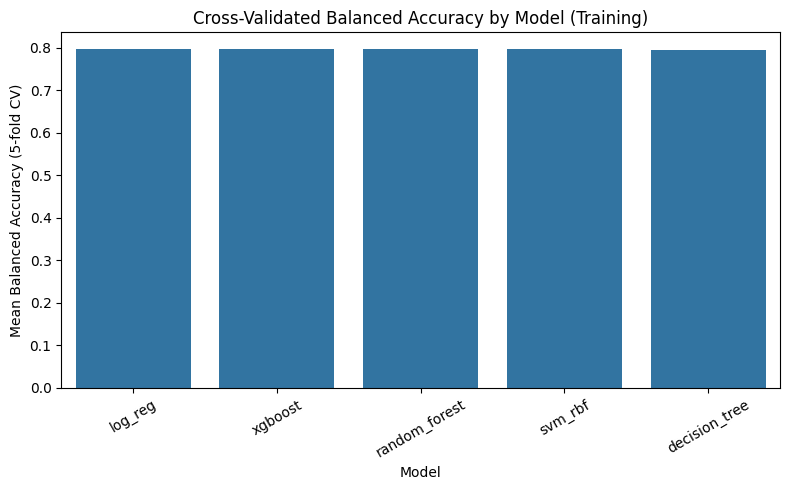

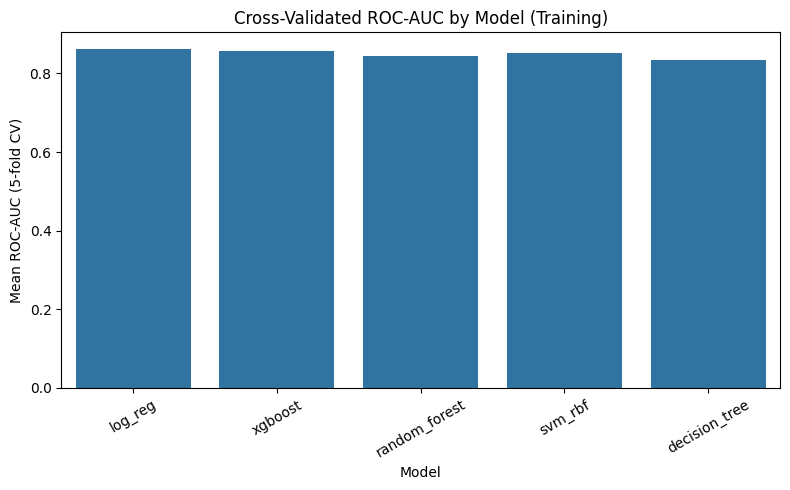

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve

# CV RESULTS – BALANCED ACCURACY + ROC-AUC

cv_plot_df = cv_results_df.sort_values("cv_bal_acc_mean", ascending=False).copy()

plt.figure(figsize=(8,5))
sns.barplot(
    data=cv_plot_df,
    x="model",
    y="cv_bal_acc_mean"
)
plt.title("Cross-Validated Balanced Accuracy by Model (Training)")
plt.ylabel("Mean Balanced Accuracy (5-fold CV)")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.barplot(
    data=cv_plot_df,
    x="model",
    y="cv_roc_auc_mean"
)
plt.title("Cross-Validated ROC-AUC by Model (Training)")
plt.ylabel("Mean ROC-AUC (5-fold CV)")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

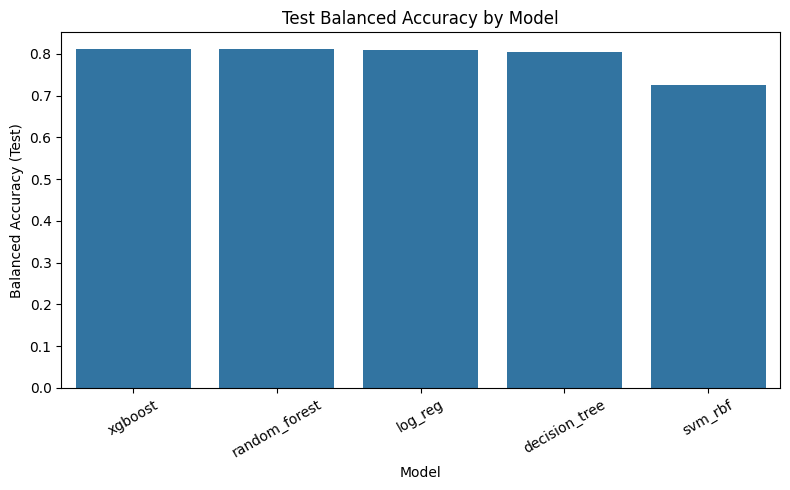

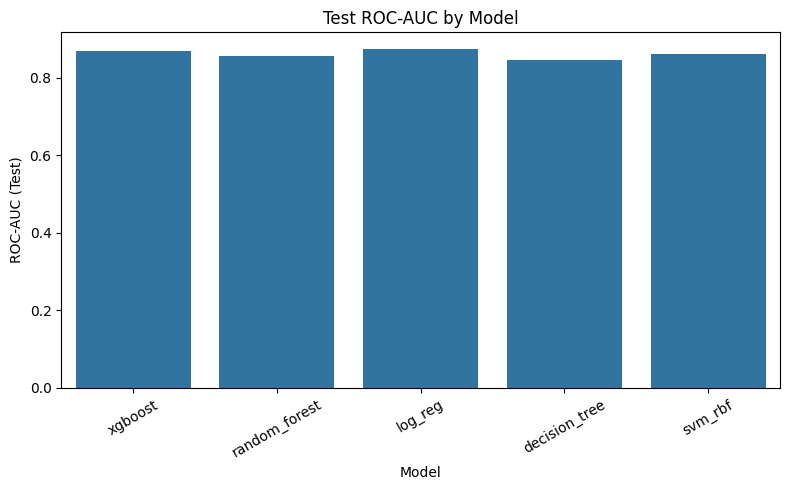

In [ ]:
# 2) TEST RESULTS – BALANCED ACCURACY + ROC-AUC

test_plot_df = test_results_df.sort_values("test_balanced_accuracy", ascending=False).copy()

plt.figure(figsize=(8,5))
sns.barplot(
    data=test_plot_df,
    x="model",
    y="test_balanced_accuracy"
)
plt.title("Test Balanced Accuracy by Model")
plt.ylabel("Balanced Accuracy (Test)")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.barplot(
    data=test_plot_df,
    x="model",
    y="test_roc_auc"
)
plt.title("Test ROC-AUC by Model")
plt.ylabel("ROC-AUC (Test)")
plt.xlabel("Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Best model on test (by balanced accuracy): xgboost


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [00:33:55] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


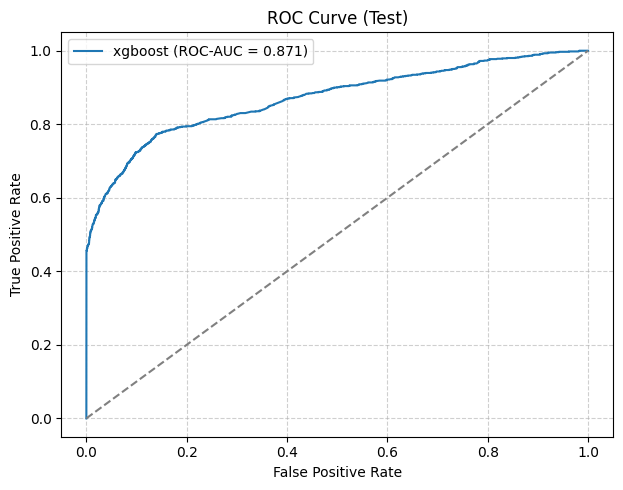

In [ ]:
# 3) PICK BEST MODEL BY TEST BALANCED ACCURACY

best_model_name = test_results_df.sort_values(
    "test_balanced_accuracy", ascending=False
).iloc[0]["model"]
best_model = best_models[best_model_name]

print("Best model on test (by balanced accuracy):", best_model_name)

# Fit on full training data
best_model.fit(X_train, y_train)

# Get probabilities on test
y_proba_best = best_model.predict_proba(X_test)[:, 1]

# ROC curve
fpr, tpr, roc_thresh = roc_curve(y_test, y_proba_best)

# PR curve (kept as a secondary diagnostic)
precisions, recalls, pr_thresh = precision_recall_curve(y_test, y_proba_best)

from sklearn.metrics import roc_auc_score, average_precision_score

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(
    fpr, tpr,
    label=f"{best_model_name} (ROC-AUC = {roc_auc_score(y_test, y_proba_best):.3f})"
)
plt.plot([0,1],[0,1],"--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test)")
plt.legend()
plt.grid(alpha=0.6, linestyle="--")

plt.tight_layout()
plt.show()

Confusion matrix for xgboost at threshold=0.5:
[[5010  573]
 [ 278  730]]
TN=5010, FP=573, FN=278, TP=730
Accuracy:          0.871
Balanced accuracy: 0.811
Precision:         0.560
Recall:            0.724


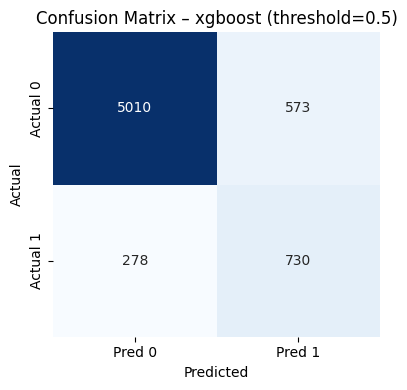

In [ ]:
# 4) CONFUSION MATRIX AT A CHOSEN THRESHOLD

from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, balanced_accuracy_score

threshold = 0.5
y_pred_best = (y_proba_best >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix for {best_model_name} at threshold={threshold}:")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy:          {accuracy_score(y_test, y_pred_best):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred_best):.3f}")
print(f"Precision:         {precision_score(y_test, y_pred_best, zero_division=0):.3f}")
print(f"Recall:            {recall_score(y_test, y_pred_best):.3f}")

plt.figure(figsize=(4,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["Actual 0", "Actual 1"],
)
plt.title(f"Confusion Matrix – {best_model_name} (threshold={threshold})")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

,threshold,precision,recall,accuracy,balanced_accuracy,tp,fp,fn,tn
0,0.10,0.162245,0.995040,0.213473,0.533701,1003,5179,5,404
1,0.15,0.180231,0.973214,0.318920,0.587001,981,4462,27,1121
2,0.20,0.211369,0.929563,0.458807,0.651688,937,3496,71,2087
3,0.25,0.277322,0.871032,0.633136,0.730608,878,2288,130,3295
4,0.30,0.421053,0.793651,0.801548,0.798312,800,1100,208,4483
5,0.35,0.480687,0.777778,0.837506,0.813034,784,847,224,4736
6,0.40,0.514208,0.753968,0.853437,0.812682,760,718,248,4865
7,0.45,0.536691,0.740079,0.862540,0.812365,746,644,262,4939
8,0.50,0.560246,0.724206,0.870885,0.810787,730,573,278,5010
9,0.55,0.583607,0.706349,0.878015,0.807679,712,508,296,5075


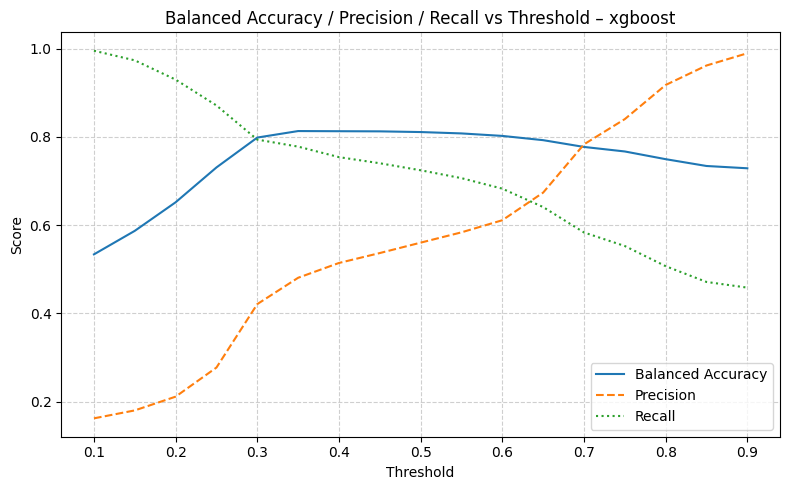

In [ ]:
# 5) THRESHOLD SWEEP

thresholds = np.linspace(0.1, 0.9, 17)

rows = []
for t in thresholds:
    y_pred_t = (y_proba_best >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, y_pred_t, zero_division=0),
        "recall": recall_score(y_test, y_pred_t),
        "accuracy": accuracy_score(y_test, y_pred_t),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred_t),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    })

thr_df = pd.DataFrame(rows)
display(thr_df)

plt.figure(figsize=(8,5))
plt.plot(thr_df["threshold"], thr_df["balanced_accuracy"], label="Balanced Accuracy")
plt.plot(thr_df["threshold"], thr_df["precision"], label="Precision", linestyle="--")
plt.plot(thr_df["threshold"], thr_df["recall"], label="Recall", linestyle=":")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title(f"Balanced Accuracy / Precision / Recall vs Threshold – {best_model_name}")
plt.legend()
plt.grid(alpha=0.6, linestyle="--")
plt.tight_layout()
plt.show()

-----------------------

## 7. Final Results & Interpretation

### Evaluation Metric

Because only ~15% of products are best-sellers, plain accuracy would be misleading.  
We therefore use **balanced accuracy** as our main evaluation metric:

**Balanced Accuracy = (TPR + TNR)/ 2**

This treats the positive (best-seller) and negative classes symmetrically and is robust to class imbalance.  

Our best model (XGBoost) achieves:

- **Balanced accuracy ≈ 0.81**
- ROC-AUC ≈ 0.87
- Precision ≈ 0.55, Recall ≈ 0.74

We focus on **balanced accuracy** for model comparison, and interpret **recall** as the key business metric (fraction of true best-sellers we successfully flag).


References

* https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
* https://github.com/duygut/Brazilian_E-Commerce_Data_Analysis
* https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html
* https://insightsoftware.com/blog/top-5-predictive-analytics-models-and-algorithms/

## Gen AI Disclosure

We used ChatGPT as a learning aid to clarify concepts related to:

- Designing a product-level prediction model
- Understanding balanced accuracy, ROC-AUC, and class imbalance
- Structuring the modeling pipeline (feature engineering → train/test split → tuning → evaluation)
- Interpreting segmentation logic (Trending vs. Balanced vs. Late-Bloomer products)
- Fixing code issues related to merging data, feature lists, preprocessing pipelines, and GridSearchCV

Prompts Used:
- “Explain whether PR-AUC or balanced accuracy is better for an imbalanced classification problem.”
- “Help me debug a KeyError in my preprocessing pipeline where a feature is missing from X_train.”
- “Suggest a slide structure that follows this project rubric.”
- “Should I apply stacking or voting ensembles for my current model performance?”
- “Explain how to interpret a threshold sweep (precision, recall, balanced accuracy).”